# 03 · Splitting and leakage

Curation decides what the model sees. Splitting decides whether the numbers
you later report mean anything. Cells are not independent samples: cells
from one donor share genetics, handling and sequencing run. This notebook
explores the splitters in `src/data/splits.py` and measures what each
protects against:

1. **Group structure** – how cells nest in donors, batches and studies
2. **Splitters** – where each donor's cells land under each strategy
3. **The leakage audit** – the check that runs before every training run
4. **What leakage buys** – the same probe scored under different splits
5. **Fit-on-train** – fitting gene selection and PCA with and without the
   test cells
6. **Refusals** – the cases where a splitter declines to produce a split
7. **Donor-level uncertainty** – why cell-level confidence intervals are
   too narrow

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

from nbutils import (set_style, load_data, pca, codes, probe_f1,
                     SERIES, BLUE, ORANGE, AQUA, NEUTRAL, MUTED, SURFACE, INK, SEQ)
from src.core.registry import SPLITTERS, autodiscover
from src.data.preprocessing import normalize_counts, select_hvg
from src.data.splits import audit_leakage
from src.eval.probes import knn_probe, linear_probe

autodiscover()
set_style()

In [2]:
DATA_PATH = None        # e.g. "/path/to/dataset.h5ad"
OBS_MAP   = None
RAW_LAYER = None

adata = load_data(DATA_PATH, OBS_MAP, RAW_LAYER, n_cells=4000, n_genes=2000,
                  n_donors=16, n_studies=4, seed=0)
IS_SYNTHETIC = bool(adata.uns.get("synthetic", False))
X = sp.csr_matrix(adata.X)
obs = adata.obs.reset_index(drop=True)
batch = obs["batch_id"].astype(str).to_numpy()
y = codes(obs["cell_type"])
lognorm_all, lib = normalize_counts(X)
print(X.shape, "| donors:", obs["donor_id"].nunique(), "| batches:", obs["batch_id"].nunique(),
      "| studies:", obs["study_id"].nunique(), "| cell types:", obs["cell_type"].nunique())

(4000, 2000) | donors: 16 | batches: 4 | studies: 4 | cell types: 8


## 1 · Group structure

Donors contribute unequal numbers of cells and sit inside batches and
studies. A splitter that holds out whole donors therefore cannot hit its
requested fractions exactly, and holding out donors does not by itself hold
out batches.

largest donor has 1.3x the cells of the smallest


,cells,batch,study,cell_types
donor_id,,,,
donor_13,277,batch_1,study_1,8
donor_05,272,batch_1,study_1,8
donor_00,265,batch_0,study_0,8
donor_02,264,batch_2,study_2,8
donor_09,262,batch_1,study_1,8
donor_10,259,batch_2,study_2,8
donor_15,257,batch_3,study_3,8
donor_08,255,batch_0,study_0,8


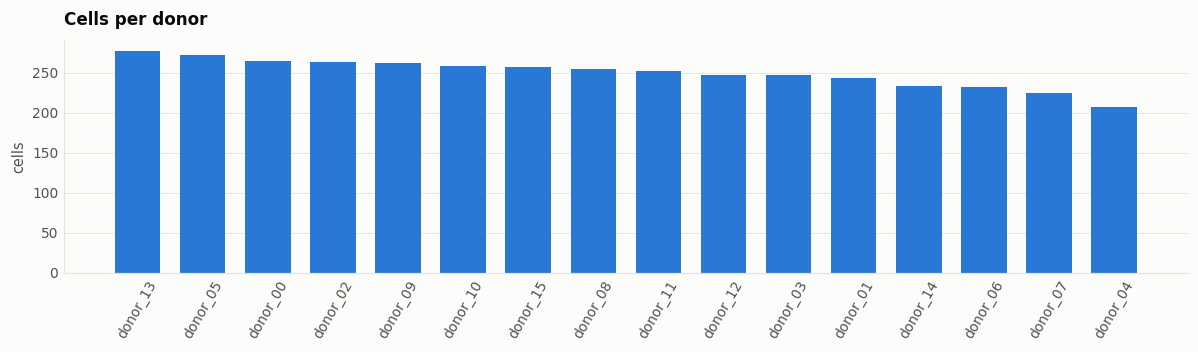

In [3]:
per_donor = obs["donor_id"].value_counts().sort_values(ascending=False)
nesting = (obs.groupby("donor_id", observed=True)
              .agg(cells=("cell_type", "size"), batch=("batch_id", "first"), study=("study_id", "first"),
                   cell_types=("cell_type", "nunique"))
              .sort_values("cells", ascending=False))

fig, ax = plt.subplots(figsize=(11, 3.3))
ax.bar(per_donor.index.astype(str), per_donor.values, color=BLUE, width=0.7)
ax.set(title="Cells per donor", ylabel="cells")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
fig.tight_layout()
print(f"largest donor has {per_donor.max() / per_donor.min():.1f}x the cells of the smallest")
nesting.head(8)

## 2 · Splitters

Four strategies, all built from the registry exactly as a config would:

| name | holds out | answers |
|---|---|---|
| `random` | individual cells | nothing about generalization; a leakage control |
| `donor_held_out` | whole donors | does it work on a new person? |
| `study_held_out` | whole studies | does it work on a new lab and protocol? |
| `tissue_held_out` | whole tissues | does it transfer to a new tissue? |

Each heatmap row is a donor; the shade is the share of that donor's cells in
each split. A held-out split has exactly one filled cell per row.

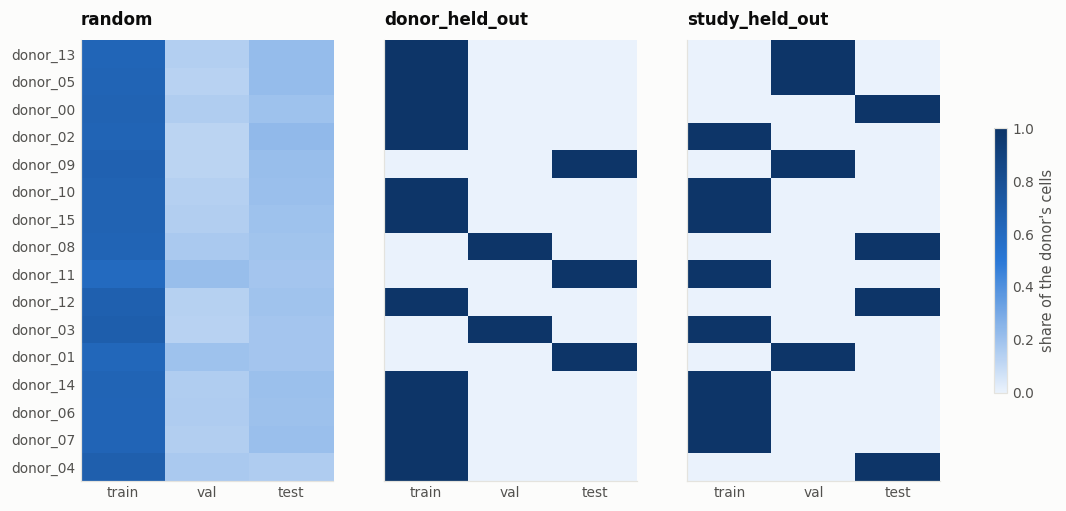

In [4]:
split_cfgs = {
    "random": {"name": "random", "val": 0.15, "test": 0.2, "seed": 0, "silence_warning": True},
    "donor_held_out": {"name": "donor_held_out", "val": 0.15, "test": 0.2, "seed": 0},
    "study_held_out": {"name": "study_held_out", "val": 0.15, "test": 0.2, "seed": 0},
}
splits = {}
for name, cfg in split_cfgs.items():
    try:
        splits[name] = SPLITTERS.build(cfg).split(obs)
    except (ValueError, KeyError) as exc:
        print(f"{name}: not available on this dataset -> {str(exc)[:110]}")

donors = per_donor.index.astype(str).tolist()
fig, ax = plt.subplots(1, len(splits), figsize=(4.2 * len(splits), 5.2), sharey=True)
ax = np.atleast_1d(ax)
for a, (name, sp_) in zip(ax, splits.items()):
    M = np.zeros((len(donors), 3))
    d = obs["donor_id"].astype(str).to_numpy()
    for j, part in enumerate(["train", "val", "test"]):
        counts = pd.Series(d[sp_[part]]).value_counts()
        M[:, j] = [counts.get(k, 0) for k in donors]
    M = M / M.sum(1, keepdims=True)
    im = a.imshow(M, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    a.set(title=name, xticks=range(3), xticklabels=["train", "val", "test"],
          yticks=range(len(donors)), yticklabels=donors)
    a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="share of the donor's cells")
plt.show()

In [5]:
def realized(sp_):
    n = sum(len(v) for v in sp_.values())
    types_train = set(obs["cell_type"].to_numpy()[sp_["train"]])
    types_test = set(obs["cell_type"].to_numpy()[sp_["test"]])
    return {
        "train %": 100 * len(sp_["train"]) / n, "val %": 100 * len(sp_["val"]) / n,
        "test %": 100 * len(sp_["test"]) / n,
        "test donors": obs["donor_id"].iloc[sp_["test"]].nunique(),
        "cell types in test": len(types_test),
        "test types unseen in train": len(types_test - types_train),
    }

print("requested: train 65% / val 15% / test 20%")
pd.DataFrame({k: realized(v) for k, v in splits.items()}).T.round(1)

requested: train 65% / val 15% / test 20%


,train %,val %,test %,test donors,cell types in test,test types unseen in train
random,65.0,15.0,20.0,16.0,8.0,0.0
donor_held_out,68.5,12.6,19.0,3.0,8.0,0.0
study_held_out,49.2,26.4,24.4,4.0,8.0,0.0


## 3 · The leakage audit

`audit_leakage` checks whether any grouping variable straddles splits. It
runs before every training run and the run stops if `donor_id` overlaps.
Batch and study overlap are reported as warnings: a donor-held-out split is
still an honest estimate of generalization to new donors, but it says
nothing about new batches or studies.

In [6]:
for name, sp_ in splits.items():
    rep = audit_leakage(obs, sp_)
    print(f"── {name} ──")
    print(rep, "\n")

── random ──
Leakage audit (LEAKAGE DETECTED)
  donor_id     shared across splits: 16
  batch_id     shared across splits: 4
  study_id     shared across splits: 4
  !! 16 'donor_id' value(s) appear in multiple splits (e.g. ['donor_00', 'donor_01', 'donor_02'])
  ~  4 'batch_id' value(s) appear in multiple splits (e.g. ['batch_0', 'batch_1', 'batch_2'])
  ~  4 'study_id' value(s) appear in multiple splits (e.g. ['study_0', 'study_1', 'study_2']) 

── donor_held_out ──
Leakage audit (CLEAN)
  donor_id     shared across splits: 0
  batch_id     shared across splits: 3
  study_id     shared across splits: 3
  ~  3 'batch_id' value(s) appear in multiple splits (e.g. ['batch_0', 'batch_1', 'batch_3'])
  ~  3 'study_id' value(s) appear in multiple splits (e.g. ['study_0', 'study_1', 'study_3']) 

── study_held_out ──
Leakage audit (CLEAN)
  donor_id     shared across splits: 0
  batch_id     shared across splits: 0
  study_id     shared across splits: 0 



## 4 · What leakage buys

The same pipeline (gene selection → log-normalization → PCA → probe) scored
under each split, repeated over several split seeds. Everything is fitted on
the training cells only, so the *only* thing that changes between the
columns is which cells are held out.

Two probes are shown because they respond differently. A linear probe needs
cell types to be linearly separable. A k-nearest-neighbour probe only needs
a test cell's neighbours to share its label, which is easier when cells from
the same donor are sitting in the training set.

,linear F1 mean,linear F1 range,kNN F1 mean,kNN F1 range
random,0.912,0.024,0.863,0.026
donor_held_out,0.908,0.037,0.858,0.048
study_held_out,0.832,0.069,0.724,0.153


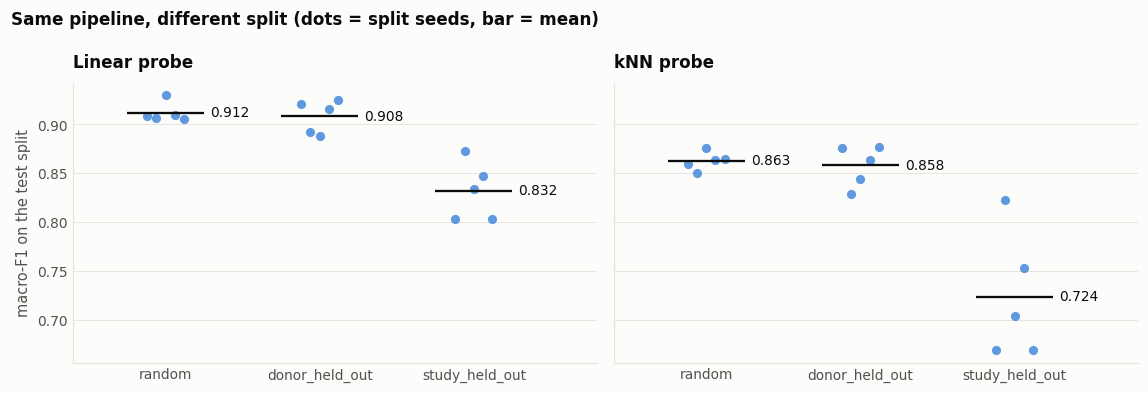

In [7]:
def embed(X_, batch_, fit, *parts, n_top=500, k=30):
    """Select genes and fit PCA on `fit` cells only; embed each index set in `parts`."""
    hv = select_hvg(X_[fit], n_top=n_top, batch=batch_[fit])
    ln = normalize_counts(X_[:, hv])[0]
    return pca(ln[fit], *[ln[p] for p in parts], k=k)[1:]

def score(X_, y_, batch_, sp_):
    tr, te = sp_["train"], sp_["test"]
    Ztr, Zte = embed(X_, batch_, tr, tr, te)
    return probe_f1(Ztr, y_[tr], Zte, y_[te]), knn_probe(Ztr, y_[tr], Zte, y_[te], n_boot=0)["macro_f1"]

SEEDS = range(5)
results = {}
for name, cfg in split_cfgs.items():
    if name not in splits:
        continue
    results[name] = np.array([score(X, y, batch, SPLITTERS.build({**cfg, "seed": s}).split(obs)) for s in SEEDS])

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for a, j, title in zip(ax, [0, 1], ["Linear probe", "kNN probe"]):
    for i, (name, vals) in enumerate(results.items()):
        a.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals[:, j],
                  s=36, color=BLUE, alpha=0.75, linewidths=0, zorder=3)
        a.hlines(vals[:, j].mean(), i - 0.25, i + 0.25, color=INK, linewidth=1.5, zorder=4)
        a.text(i + 0.29, vals[:, j].mean(), f"{vals[:, j].mean():.3f}", va="center", fontsize=9, color=INK)
    a.set(title=title, xticks=range(len(results)), xticklabels=list(results), xlim=(-0.6, len(results) - 0.2))
    a.grid(axis="x", visible=False)
ax[0].set_ylabel("macro-F1 on the test split")
fig.suptitle("Same pipeline, different split (dots = split seeds, bar = mean)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()

summary = pd.DataFrame({name: {"linear F1 mean": v[:, 0].mean(), "linear F1 range": np.ptp(v[:, 0]),
                               "kNN F1 mean": v[:, 1].mean(), "kNN F1 range": np.ptp(v[:, 1])}
                        for name, v in results.items()}).T
summary.round(3)

**Reading it.** The gap between `random` and the held-out columns is the
part of the score that came from having the test donors' other cells in
training. Note the spread as well as the mean: held-out splits vary more
from seed to seed because each seed holds out *different donors*, which is
the real source of uncertainty (section 7).

How large the gap is depends on how strongly donors differ. On synthetic
data that is a knob, so the dependence can be drawn directly.

,linear: random − held-out,kNN: random − held-out
donor_effect,,
0.00,0.014,-0.006
0.25,0.014,0.058
0.50,0.039,0.029
1.00,0.114,0.091


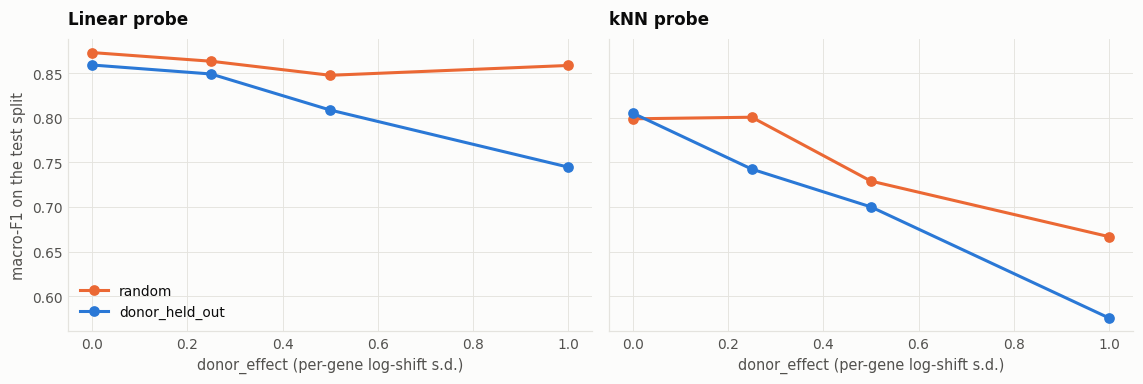

In [8]:
if IS_SYNTHETIC:
    levels = [0.0, 0.25, 0.5, 1.0]
    sweep = {"random": [], "donor_held_out": []}
    for de in levels:
        acc = {k: [] for k in sweep}
        for seed in range(3):
            a = load_data(n_cells=2000, n_genes=1200, n_donors=12, donor_effect=de, seed=10 + seed)
            Xa, oa = sp.csr_matrix(a.X), a.obs.reset_index(drop=True)
            ya, ba = codes(oa["cell_type"]), oa["batch_id"].astype(str).to_numpy()
            for name in sweep:
                acc[name].append(score(Xa, ya, ba, SPLITTERS.build({**split_cfgs[name], "seed": seed}).split(oa)))
        for name in sweep:
            sweep[name].append(np.mean(acc[name], axis=0))

    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
    for a, j, title in zip(ax, [0, 1], ["Linear probe", "kNN probe"]):
        for (name, vals), color in zip(sweep.items(), [ORANGE, BLUE]):
            a.plot(levels, np.array(vals)[:, j], marker="o", color=color, label=name)
        a.set(title=title, xlabel="donor_effect (per-gene log-shift s.d.)")
    ax[0].set_ylabel("macro-F1 on the test split")
    ax[0].legend(loc="lower left")
    fig.tight_layout()
    gap = np.array(sweep["random"]) - np.array(sweep["donor_held_out"])
    display(pd.DataFrame(gap, index=pd.Index(levels, name="donor_effect"),
                         columns=["linear: random − held-out", "kNN: random − held-out"]).round(3))
else:
    print("Real data loaded: donor-effect sweep skipped.")

## 5 · Fit-on-train

Splitting cells is not enough if statistics are estimated on all of them.
Gene selection, PCA loadings, scalers, tokenizer medians and label encoders
are all "fitted". The comparison below fits gene selection and PCA either on
the training cells or on train + test, and scores the same held-out donors.

For an unsupervised linear pipeline the effect is usually small. It grows
with model capacity and with anything fitted using labels. The repo fits
everything on train regardless, because the cost of doing so is zero.

In [9]:
rows = []
for s in SEEDS:
    sp_ = SPLITTERS.build({**split_cfgs["donor_held_out"], "seed": s}).split(obs)
    tr, te = sp_["train"], sp_["test"]
    Ztr, Zte = embed(X, batch, tr, tr, te)
    clean = probe_f1(Ztr, y[tr], Zte, y[te])
    both = np.concatenate([tr, te])
    Ztr2, Zte2 = embed(X, batch, both, tr, te)
    leaky = probe_f1(Ztr2, y[tr], Zte2, y[te])
    rows.append({"seed": s, "fit on train": clean, "fit on train + test": leaky, "difference": leaky - clean})
fit_df = pd.DataFrame(rows).set_index("seed")
print(f"mean difference (leaky − clean): {fit_df['difference'].mean():+.4f}   "
      f"seed-to-seed spread of the clean score: {fit_df['fit on train'].std():.4f}")
fit_df.round(4)

mean difference (leaky − clean): -0.0050   seed-to-seed spread of the clean score: 0.0171


,fit on train,fit on train + test,difference
seed,,,
0,0.9207,0.9226,0.0019
1,0.8920,0.8868,-0.0052
2,0.8881,0.8957,0.0077
3,0.9160,0.9009,-0.0152
4,0.9251,0.9108,-0.0143


## 6 · Refusals

A splitter that cannot do what its name promises raises instead of quietly
producing something weaker. These are the three cases.

In [10]:
def attempt(label, fn):
    try:
        fn()
        print(f"{label}: ran")
    except Exception as exc:
        print(f"{label}:\n   {type(exc).__name__}: {str(exc)[:230]}\n")

one_donor = obs.assign(donor_id="unknown")
attempt("donor-held-out when every cell has the same donor label",
        lambda: SPLITTERS.build({"name": "donor_held_out"}).split(one_donor))

two = obs[obs["donor_id"].isin(per_donor.index[:2])].reset_index(drop=True)
attempt("donor-held-out with only two donors",
        lambda: SPLITTERS.build({"name": "donor_held_out"}).split(two))

from src.core.registry import TOKENIZERS
tok = TOKENIZERS.build({"name": "rank"})
tok.fit(lognorm_all[splits["donor_held_out"]["train"]])
attempt("re-fitting a rank tokenizer on a second split",
        lambda: tok.fit(lognorm_all[splits["donor_held_out"]["test"]]))

donor-held-out when every cell has the same donor label:
   ValueError: obs['donor_id'] has a single value ('unknown'): this dataset carries no donor_id structure, so a held-out split on it would be a random split wearing a rigorous name. Use a source that supplies real labels, or pass allow_fabricate

donor-held-out with only two donors:
   ValueError: need >= 3 distinct 'donor_id' values to make train/val/test; found 2.

re-fitting a rank tokenizer on a second split:
   RuntimeError: RankTokenizer is already fitted. Re-fitting on a different split would leak statistics across the split boundary; construct a new tokenizer instead.



## 7 · Donor-level uncertainty

With thousands of test cells a bootstrap over cells gives a very tight
interval. But the question is how the model does on *a new donor*, and the
test split contains only a handful of those. Scoring each held-out donor
separately shows the spread the cell-level interval hides.

pooled F1 0.878, cell-bootstrap interval width 0.033
per-donor F1 ranges 0.799–0.915 (width 0.116) across 6 held-out donors


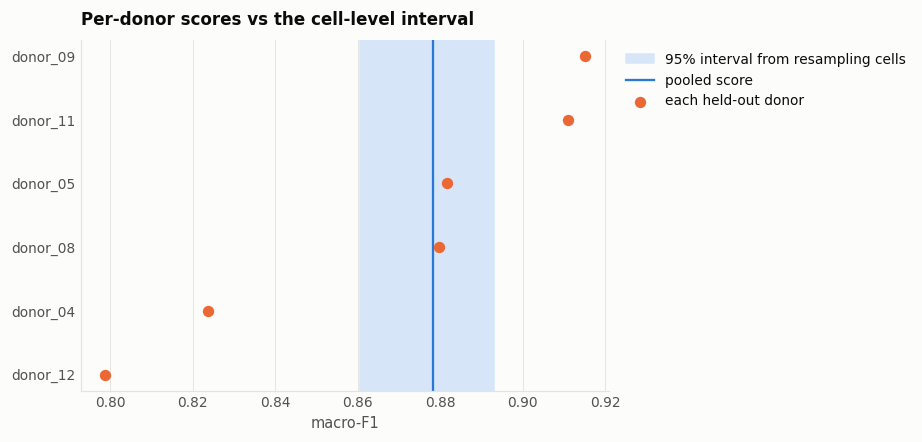

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

sp_ = SPLITTERS.build({"name": "donor_held_out", "val": 0.1, "test": 0.4, "seed": 0}).split(obs)
tr, te = sp_["train"], sp_["test"]
Ztr, Zte = embed(X, batch, tr, tr, te)
pooled = linear_probe(Ztr, y[tr], Zte, y[te], n_boot=300)

scaler = StandardScaler().fit(Ztr)
clf = LogisticRegression(max_iter=2000).fit(scaler.transform(Ztr), y[tr])
pred = clf.predict(scaler.transform(Zte))
test_donor = obs["donor_id"].astype(str).to_numpy()[te]
per = pd.Series({d: f1_score(y[te][test_donor == d], pred[test_donor == d], average="macro", zero_division=0)
                 for d in np.unique(test_donor)}).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(per) + 1.6))
ax.axvspan(pooled["macro_f1_lo"], pooled["macro_f1_hi"], color="#d6e6f8", label="95% interval from resampling cells")
ax.axvline(pooled["macro_f1"], color=BLUE, linewidth=1.5, label="pooled score")
ax.scatter(per.values, range(len(per)), s=55, color=ORANGE, zorder=3, linewidths=0, label="each held-out donor")
ax.set(title="Per-donor scores vs the cell-level interval", xlabel="macro-F1",
       yticks=range(len(per)), yticklabels=per.index)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()

print(f"pooled F1 {pooled['macro_f1']:.3f}, cell-bootstrap interval width "
      f"{pooled['macro_f1_hi'] - pooled['macro_f1_lo']:.3f}")
print(f"per-donor F1 ranges {per.min():.3f}–{per.max():.3f} (width {per.max() - per.min():.3f}) "
      f"across {len(per)} held-out donors")

## What to carry forward

- A held-out split gives up exact split fractions in exchange for a number
  that means something. Check the realized fractions and the cell types
  present in test.
- The random-versus-held-out gap is dataset-specific. Measure it with
  `python run.py +experiment=leakage_ablation` rather than assuming it.
- Report how many donors were held out. If per-donor scores spread further
  than the cell-level interval, the interval is not the uncertainty.
- Donor-held-out does not cover batch or study shift. Use
  `data/splitter=study_held_out` when the claim is about new labs.